# Introduction to Neural Networks

## 1. Images become numbers
Each image has 8 × 8 pixels. The dataset uses intensities from 0 to 16; we divide by 16 to get inputs in [0,1]. A network maps these 64 numbers to ten digit probabilities.

1077 training / 360 validation / 360 test images


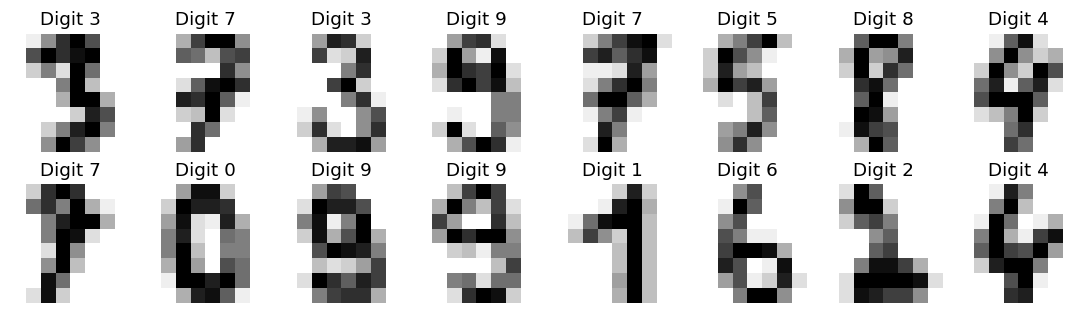

In [ ]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from sklearn.exceptions import ConvergenceWarning

try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
digits = load_digits()
X = digits.data.astype(float) / 16.0
y = digits.target
# Split indices once so images, labels and predictions stay aligned.
development, test_idx = train_test_split(
    np.arange(len(y)), test_size=0.2, stratify=y, random_state=42)
train_idx, val_idx = train_test_split(
    development, test_size=0.25, stratify=y[development], random_state=42)
print(f"{len(train_idx)} training / {len(val_idx)} validation / {len(test_idx)} test images")
fig, axes = plt.subplots(2, 8, figsize=(10, 3))
for ax, idx in zip(axes.flat, train_idx[:16]):
    ax.imshow(X[idx].reshape(8, 8), cmap="binary", vmin=0, vmax=1)
    ax.set_title(f"Digit {y[idx]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Train your network
The hidden layer computes $h_i=\sigma(\mathbf w_i^T\mathbf x+b_i)$. The output layer computes scores $z_k=\sum_i v_{ki}h_i+c_k$, then applies **softmax**.

Try 5 versus 100 neurons, sigmoid versus ReLU, and different seeds. Compare using **validation accuracy**. Save the test set until the end. Changing several settings at once makes results harder to interpret.

“SGD” below has momentum disabled, for a clearer comparison with Adam. It uses minibatches, so it is stochastic rather than full-batch gradient descent.

In [ ]:
neurons = widgets.IntSlider(value=32, min=5, max=100, step=5,
                            description="Neurons:", continuous_update=False)
activation = widgets.Dropdown(
    options=[("Sigmoid", "logistic"), ("Tanh", "tanh"),
             ("ReLU", "relu"), ("Linear", "identity")],
    value="logistic", description="Activation:")
solver = widgets.Dropdown(options=["adam", "sgd"], description="Optimiser:")
rate = widgets.FloatLogSlider(value=0.01, base=10, min=-4, max=-1, step=0.5,
                              description="Step size:", readout_format=".4f")
epochs = widgets.IntSlider(value=200, min=50, max=500, step=50,
                           description="Max epochs:")
seed = widgets.IntSlider(value=1, min=0, max=20, description="Seed:")
train_button = widgets.Button(description="Train network", button_style="success")
training_output = widgets.Output()
state = {"model": None, "version": 0}
history = []

def train_network(_=None):
    train_button.disabled = True
    try:
        with training_output:
            clear_output(wait=True)
            print("Training...")
            candidate = MLPClassifier(
                hidden_layer_sizes=(neurons.value,), activation=activation.value,
                solver=solver.value, learning_rate_init=rate.value,
                max_iter=epochs.value, random_state=seed.value,
                batch_size=64, alpha=1e-4, momentum=0.0,
                nesterovs_momentum=False, early_stopping=False)
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always", ConvergenceWarning)
                candidate.fit(X[train_idx], y[train_idx])
            state["model"] = candidate
            state["version"] += 1
            train_acc = candidate.score(X[train_idx], y[train_idx])
            val_acc = candidate.score(X[val_idx], y[val_idx])
            probs = candidate.predict_proba(X[val_idx])
            assert candidate.out_activation_ == "softmax"
            assert np.allclose(probs.sum(axis=1), 1)
            history.append((neurons.value, activation.value, solver.value,
                            rate.value, seed.value, val_acc))
            clear_output(wait=True)
            print(f"Training accuracy: {train_acc:.1%} | Validation accuracy: {val_acc:.1%}")
            print(f"Epochs: {candidate.n_iter_} | Output activation: {candidate.out_activation_}")
            if any(issubclass(w.category, ConvergenceWarning) for w in caught):
                print("Epoch limit reached before convergence; try more epochs or another step size.")
            fig, ax = plt.subplots(figsize=(6, 2.5))
            ax.plot(candidate.loss_curve_, color="teal")
            ax.set(xlabel="Epoch", ylabel="Training loss", title="Learning from examples")
            plt.tight_layout()
            plt.show()
            print("Recent experiments (validation accuracy):")
            for n, a, s, lr, rs, acc in history[-5:]:
                print(f"{n:3} neurons | {a:8} | {s:4} | step={lr:g} | seed={rs}: {acc:.1%}")
    except Exception as exc:
        with training_output:
            print(f"Training failed: {exc}. Any previous model remains available.")
    finally:
        train_button.disabled = False

train_button.on_click(train_network)
display(widgets.VBox([widgets.HBox([neurons, activation]),
                      widgets.HBox([solver, rate]), widgets.HBox([epochs, seed]),
                      train_button, training_output]))
train_network()

## 3. You versus the network
These are **validation images**. Choose a digit, then reveal the network's answer and probability chart. Press **Next image** for another example.

The model's probabilities express its confidence; they are not guaranteed to be calibrated. A confident model can still be wrong.

In [ ]:
game_rng = np.random.default_rng(123)
game = {"idx": int(game_rng.choice(val_idx)), "revealed": False,
        "correct": 0, "total": 0}
guess = widgets.ToggleButtons(options=list(range(10)), description="Your guess:")
reveal = widgets.Button(description="Reveal prediction", button_style="info")
next_button = widgets.Button(description="Next image")
game_output = widgets.Output()

def show_game(revealed=False):
    idx = game["idx"]
    with game_output:
        clear_output(wait=True)
        fig, axes = plt.subplots(1, 2, figsize=(9, 3))
        axes[0].imshow(X[idx].reshape(8, 8), cmap="binary", vmin=0, vmax=1)
        axes[0].axis("off")
        if revealed:
            model = state["model"]
            p = model.predict_proba(X[idx:idx+1])[0]
            prediction = int(model.classes_[np.argmax(p)])
            axes[0].set_title(f"Your guess: {guess.value} | Actual: {y[idx]}")
            colors = ["teal" if k == prediction else "lightgray" for k in model.classes_]
            axes[1].bar(model.classes_, p, color=colors)
            axes[1].set(xticks=range(10), ylim=(0, 1), xlabel="Digit",
                        ylabel="Probability", title=f"Network predicts {prediction}")
        else:
            axes[0].set_title("Which digit is this?")
            axes[1].axis("off")
            axes[1].text(.5, .5, "Make your guess, then reveal!",
                         ha="center", va="center", transform=axes[1].transAxes)
        plt.tight_layout()
        plt.show()
        print(f"Your score: {game['correct']} / {game['total']}")

def reveal_answer(_):
    if state["model"] is None or game["revealed"]:
        return
    game["revealed"] = True
    game["total"] += 1
    game["correct"] += int(guess.value == y[game["idx"]])
    guess.disabled = True
    reveal.disabled = True
    show_game(True)

def next_image(_):
    game["idx"] = int(game_rng.choice(val_idx))
    game["revealed"] = False
    guess.disabled = False
    reveal.disabled = False
    show_game(False)

reveal.on_click(reveal_answer)
next_button.on_click(next_image)
display(widgets.VBox([guess, widgets.HBox([reveal, next_button]), game_output]))
show_game()

## 4. What did the hidden neurons learn?
Each hidden neuron has 64 input weights, which can be arranged as an 8 × 8 image. These are **weights, not digit prototypes**: the bias, activation and output weights also matter. Colours use one shared scale. Click again after retraining.

In [ ]:
weights_button = widgets.Button(description="Show hidden weights")
weights_output = widgets.Output()
def show_weights(_=None):
    model = state["model"]
    if model is None:
        return
    weights = model.coefs_[0].T
    count = min(20, len(weights))
    rows = (count + 4) // 5
    limit = max(float(np.abs(weights).max()), 1e-8)

    with weights_output:
        clear_output(wait=True)
        fig, axes = plt.subplots(
            rows, 5, figsize=(9, 1.8 * rows), squeeze=False
        )
        for i, ax in enumerate(axes.flat):
            ax.axis("off")
            if i < count:
                ax.imshow(
                    weights[i].reshape(8, 8),
                    cmap="coolwarm_r",
                    vmin=-limit,
                    vmax=limit,
                )
                ax.set_title(f"Neuron {i + 1}", fontsize=10)
        fig.suptitle("Blue: positive weights | Red: negative weights")
        plt.tight_layout()
        plt.show()
weights_button.on_click(show_weights)
display(weights_button, weights_output)

Button(description='Show hidden weights', style=ButtonStyle())

Output()

## 5. Final evaluation — use once you have chosen your settings
Click to evaluate the current model on the held-out **test set**. Do not use this score to choose settings; doing so turns the test set into another validation set.

The confusion matrix shows which digits the model confuses. The image grid uses the same test indices as the predictions.

In [ ]:
test_button = widgets.Button(description="Evaluate on test set", button_style="warning")
test_output = widgets.Output()
def evaluate_test(_=None):
    model = state["model"]
    if model is None:
        return
    with test_output:
        clear_output(wait=True)
        predictions = model.predict(X[test_idx])
        print(f"Test accuracy: {accuracy_score(y[test_idx], predictions):.1%}")
        fig, ax = plt.subplots(figsize=(5, 4))
        ConfusionMatrixDisplay.from_predictions(
            y[test_idx], predictions, labels=range(10), ax=ax,
            cmap="Blues", colorbar=False)
        plt.tight_layout()
        plt.show()
        wrong = np.flatnonzero(predictions != y[test_idx])
        selected = wrong[:8] if len(wrong) else np.arange(8)
        fig, axes = plt.subplots(1, len(selected), figsize=(12, 2), squeeze=False)
        for ax, position in zip(axes.flat, selected):
            idx = test_idx[position]
            ax.imshow(X[idx].reshape(8, 8), cmap="binary", vmin=0, vmax=1)
            ax.set_title(f"True {y[idx]}\nPred {predictions[position]}")
            ax.axis("off")
        fig.suptitle("Mistakes" if len(wrong) else "No test mistakes: sample predictions")
        plt.tight_layout()
        plt.show()
test_button.on_click(evaluate_test)
display(test_button, test_output)

Button(button_style='warning', description='Evaluate on test set', style=ButtonStyle())

Output()